In [1]:
import os

import pandas


RESULT_PATH_PREFIX = 'benchmark_sample_aris_df_threshold'


results_csv_paths = [
    subpath
    for subpath in os.listdir()
    if subpath.startswith(RESULT_PATH_PREFIX) and 'split' in subpath and '1000' not in subpath
]

results_csvs = [
    pandas.read_csv(subpath)
    for subpath in results_csv_paths
]

In [2]:
from dataclasses import dataclass


@dataclass
class BenchmarkExperimentParams:
    threshold: float
    run: int
    layer_size: int
    intermediate_layer_size: int
    latent_size: int
    num_heads: int
        
    @staticmethod
    def from_path(path):
        threshold = float(path.split('_')[5])
        run = int(path.split('_')[7])
        layer_size = int(path.split('_')[8])
        intermediate_layer_size = int(path.split('_')[9])
        latent_size = int(path.split('_')[10])
        num_heads = int(path.split('_')[11].split('.')[0])
        return BenchmarkExperimentParams(
            threshold=threshold,
            intermediate_layer_size=intermediate_layer_size,
            run=run,
            layer_size=layer_size,
            latent_size=latent_size,
            num_heads=num_heads,
        )
    


def parse_path(path: str):
    threshold = float(path.split('_')[5])
    run = int(path.split('_')[7])
    layer_size = int(path.split('_')[8])
    intermediate_layer_size = int(path.split('_')[9])
    latent_size = int(path.split('_')[10])
    num_heads = int(path.split('_')[11].split('.')[0])
    return threshold, run, layer_size, intermediate_layer_size, latent_size, num_heads
    
results_csv_paths[0], parse_path(results_csv_paths[0])

('benchmark_sample_aris_df_threshold_5.0_run_3_256_512_256_8_split.csv',
 (5.0, 3, 256, 512, 256, 8))

In [3]:
ACCEPTED_THRESHOLDS = [5.]


final_result_csvs = []


for path, csv in zip(results_csv_paths, results_csvs):
    bep = BenchmarkExperimentParams.from_path(path)
    if bep.threshold not in ACCEPTED_THRESHOLDS:
        continue
    for el, val in bep.__dict__.items():
        csv[el] = val
    csv['params'] = str([val for key, val in bep.__dict__.items() if key not in ['run', 'threshold']])
    final_result_csvs.append(csv)

In [4]:
bep.__dict__.items()

dict_items([('threshold', 4.0), ('run', 0), ('layer_size', 64), ('intermediate_layer_size', 128), ('latent_size', 32), ('num_heads', 8)])

In [5]:
full_result_csv = pandas.concat(final_result_csvs, ignore_index=True)

In [6]:
full_result_csv['params_full'] = full_result_csv['params'] + ' ' + full_result_csv['PLDA']

In [7]:
ALL_COLUMNS = [
    '151673', '151672', '151507', '151508', '151669', '151509', '151671',
    '151510', '151670', '151674', '151675', '151676'
]

FULL_SAMPLE_COLS = ['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676']

TRAIN_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

TEST_SAMPLES = [sample for sample in FULL_SAMPLE_COLS if sample not in TRAIN_SAMPLES]

In [8]:
full_result_csv_rg = full_result_csv.groupby(['run', 'params_full', 'threshold'])[FULL_SAMPLE_COLS].mean()

In [9]:
full_result_csv_rg['total_test'] = full_result_csv_rg[TEST_SAMPLES].median(axis=1)
full_result_csv_rg['total_train'] = full_result_csv_rg[TRAIN_SAMPLES].median(axis=1)

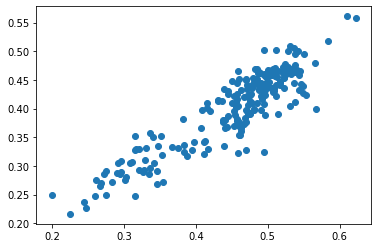

In [11]:
import matplotlib.pyplot as plt

plt.scatter(
    full_result_csv_rg['total_train'],
    full_result_csv_rg['total_test']
)

In [12]:
idx = full_result_csv_rg.groupby(['params_full', 'threshold'])['total_train'].idxmax()
full_result_csv_rg_selected = full_result_csv_rg.loc[idx]

#full_result_csv_rg_selected = full_result_csv_rg.groupby()['total_test'].max()
#full_result_csv_rg_selected = full_result_csv_rg_selected.to_frame().reset_index()

In [13]:
full_result_csv_rg = full_result_csv_rg.reset_index()

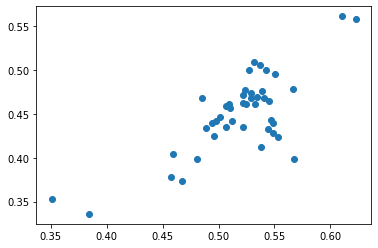

In [41]:
plt.scatter(
    full_result_csv_rg_selected['total_train'],
    full_result_csv_rg_selected['total_test']
)

In [42]:
full_result_csv_rg_selected['total_test'].max()

0.561145135619255

In [17]:
full_result_csv_rg

,run,params_full,threshold,151673,151672,151507,151508,151669,151509,151671,151510,151670,151674,151675,151676,total_test,total_train
0,0,"[128, 256, 128, 4] coarse",5.0,0.546017,0.497451,0.544806,0.527326,0.390757,0.445818,0.473854,0.464776,0.394958,0.395664,0.499448,0.512598,0.464776,0.544806
1,0,"[128, 256, 128, 4] standard",5.0,0.504959,0.538495,0.542765,0.501815,0.325384,0.482297,0.472042,0.453590,0.349243,0.438380,0.502252,0.464612,0.464612,0.538495
2,0,"[128, 256, 128, 8] coarse",5.0,0.260297,0.371118,0.236917,0.275838,0.304646,0.210978,0.329774,0.216242,0.315862,0.253373,0.280812,0.253163,0.275838,0.260297
3,0,"[128, 256, 128, 8] standard",5.0,0.474525,0.471477,0.466975,0.460440,0.410759,0.433771,0.409647,0.408849,0.421846,0.492504,0.542950,0.473600,0.433771,0.471477
4,0,"[128, 256, 64, 4] coarse",5.0,0.476705,0.480806,0.512556,0.474412,0.379203,0.386364,0.398718,0.394334,0.364516,0.399133,0.487498,0.480383,0.398718,0.480806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,4,"[64, 128, 64, 8] standard",5.0,0.496078,0.524304,0.486622,0.411106,0.331797,0.380552,0.426143,0.387161,0.355338,0.389028,0.455219,0.469238,0.389028,0.496078
216,4,"[64, 256, 32, 4] coarse",5.0,0.537891,0.530003,0.566395,0.539866,0.434014,0.506685,0.424604,0.495520,0.402758,0.448549,0.512797,0.508217,0.495520,0.537891
217,4,"[64, 256, 32, 4] standard",5.0,0.469757,0.497387,0.577791,0.564887,0.455612,0.471218,0.524690,0.464723,0.403103,0.367222,0.453546,0.453793,0.455612,0.497387
218,4,"[64, 256, 32, 8] coarse",5.0,0.306999,0.262976,0.294243,0.279816,0.122802,0.369808,0.198419,0.321618,0.093752,0.286155,0.308043,0.295655,0.286155,0.294243


In [18]:
#full_result_csv = full_result_csv.groupby(['threshold'])[FULL_SAMPLE_COLS].median().reset_index()

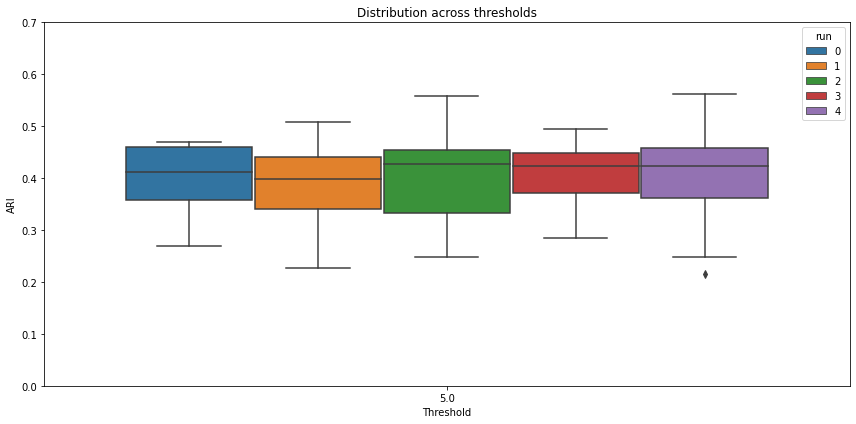

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns


TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

NON_TEST_SAMPLES = [col for col in ALL_COLUMNS if col not in TEST_SAMPLES]

df_long = full_result_csv_rg.melt(
    id_vars=["threshold", 'run'],
    value_vars=['total_test'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='run')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 0.7])

plt.tight_layout()
plt.show()

In [20]:
full_result_csv_rg['PLDA'] = full_result_csv_rg['params_full'].apply(lambda x: x.split(' ')[-1])
full_result_csv_rg['LS'] = full_result_csv_rg['params_full'].apply(lambda x: x.split(' ')[0][1:-1])
full_result_csv_rg['HLS'] = full_result_csv_rg['params_full'].apply(lambda x: x.split(' ')[1][:-1])
full_result_csv_rg['Lat.S.'] = full_result_csv_rg['params_full'].apply(lambda x: x.split(' ')[2][:-1])
full_result_csv_rg['Heads'] = full_result_csv_rg['params_full'].apply(lambda x: x.split(' ')[3][:-1])

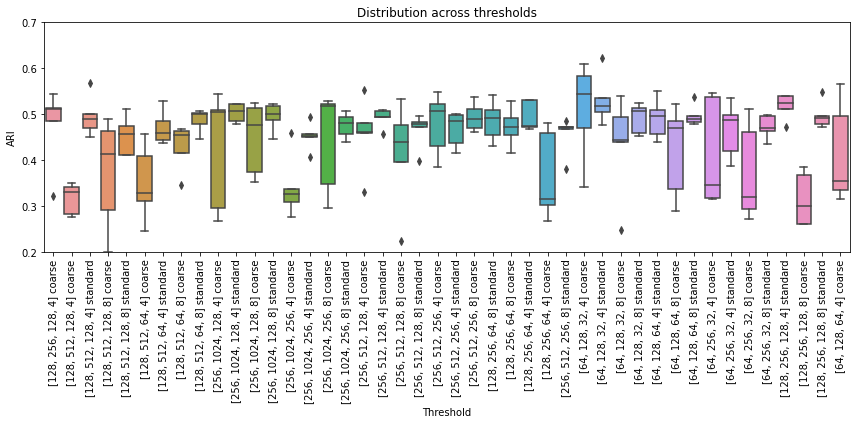

In [21]:
df_long = full_result_csv_rg.melt(
    id_vars=["threshold", 'params_full'],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="params_full", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0.2, 0.7])

plt.tight_layout()
plt.show()

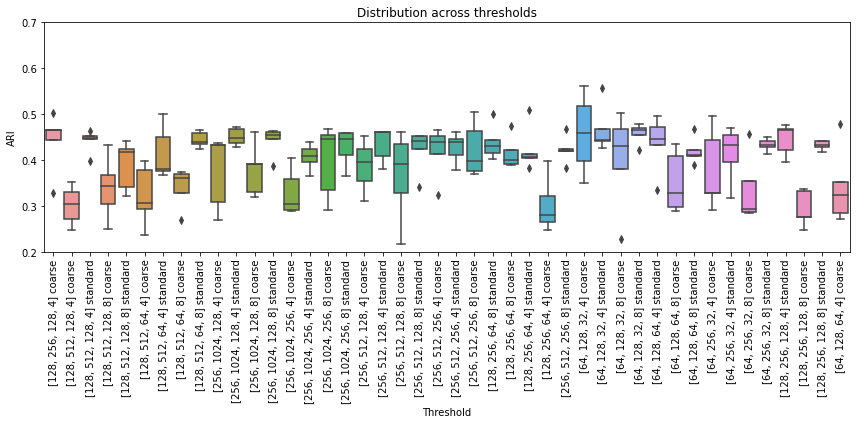

In [40]:
df_long = full_result_csv_rg.melt(
    id_vars=["threshold", 'params_full'],
    value_vars=['total_test'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="params_full", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0.2, 0.7])

plt.tight_layout()
plt.show()

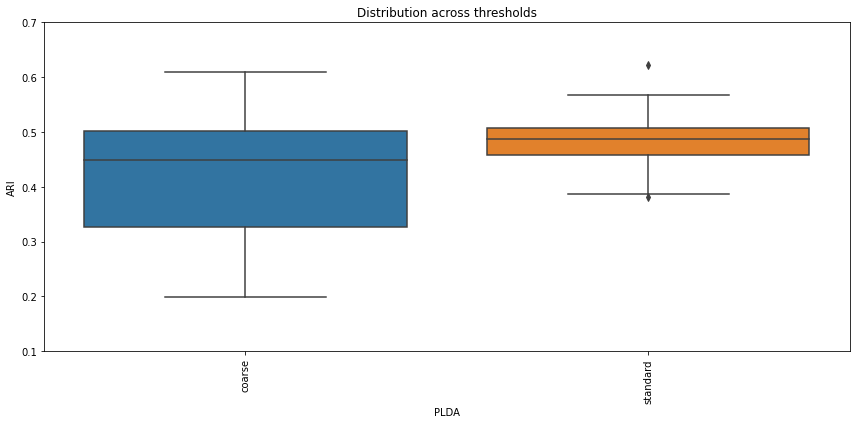

In [22]:
df_long = full_result_csv_rg.melt(
    id_vars=['PLDA'],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


#df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="PLDA", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("PLDA")
plt.ylabel("ARI")
plt.ylim([0.1, 0.7])

plt.tight_layout()
plt.show()

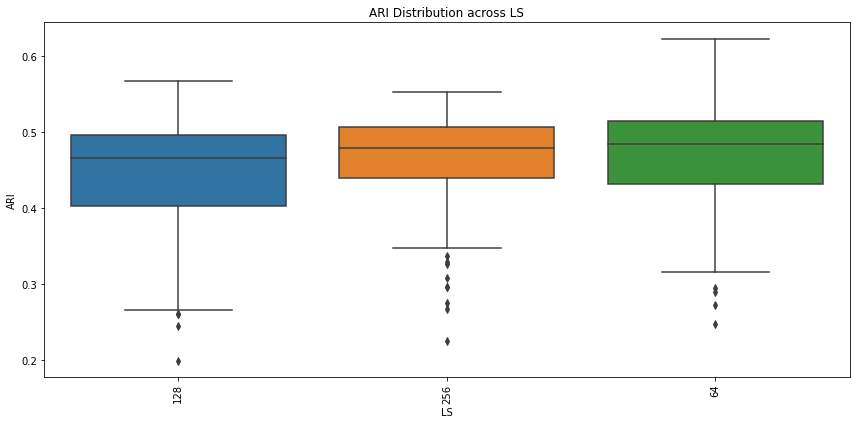

In [36]:
FEATURE = 'LS'

df_long = full_result_csv_rg.melt(
    id_vars=[FEATURE],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


#df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x=FEATURE, y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"ARI Distribution across {FEATURE}")
plt.xlabel(FEATURE)
plt.ylabel("ARI")
#plt.ylim([0.1, 0.7])

plt.tight_layout()
plt.show()

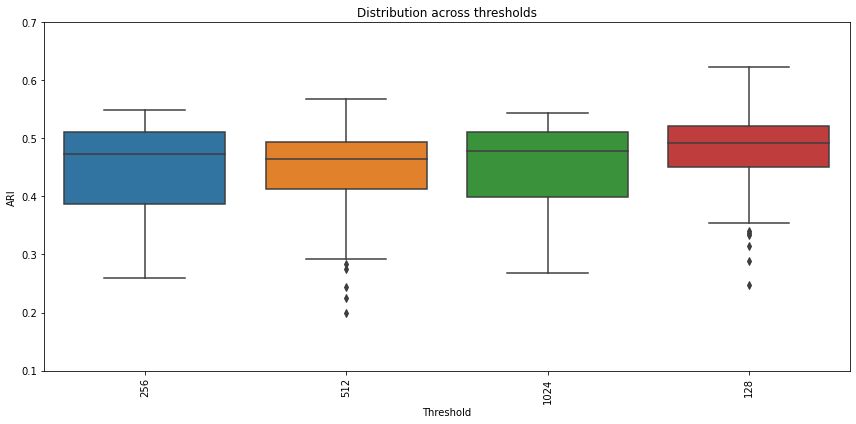

In [37]:
df_long = full_result_csv_rg.melt(
    id_vars=['HLS'],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


#df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="HLS", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0.1, 0.7])

plt.tight_layout()
plt.show()

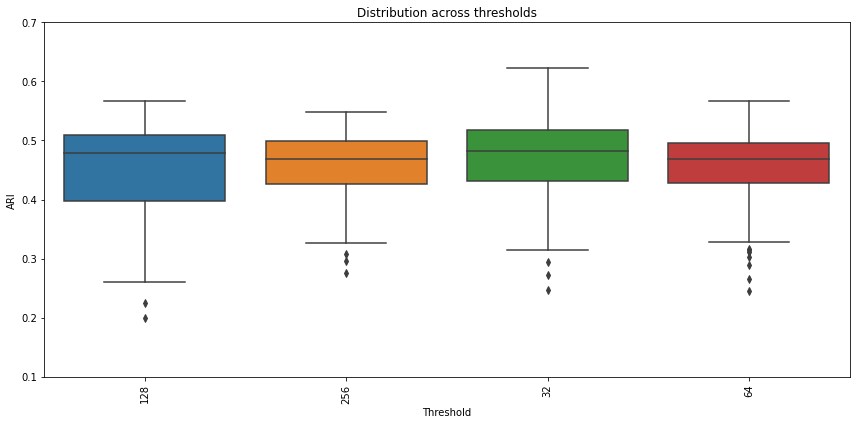

In [38]:
df_long = full_result_csv_rg.melt(
    id_vars=['Lat.S.'],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('Lat.S.')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="Lat.S.", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0.1, 0.7])

plt.tight_layout()
plt.show()

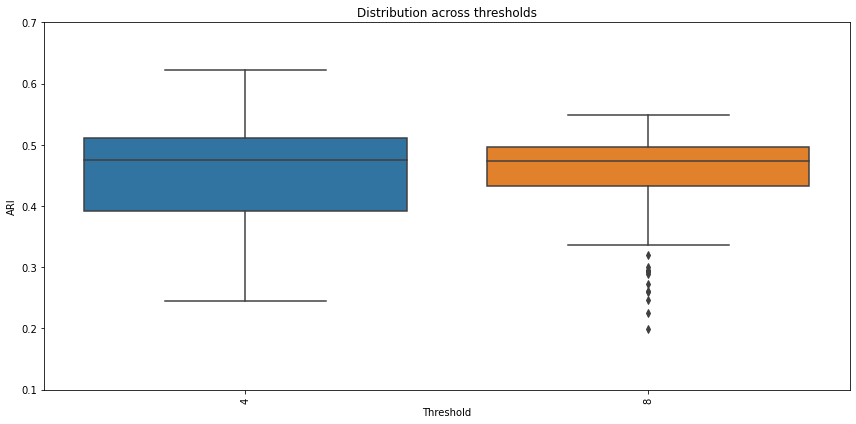

In [39]:
df_long = full_result_csv_rg.melt(
    id_vars=['Heads'],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


#df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="Heads", y="value")
ax = plt.gca()
ax.xaxis.set_tick_params(rotation=90)
plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0.1, 0.7])

plt.tight_layout()
plt.show()

In [28]:
current_results = full_result_csv_rg 
df_long = current_results.melt(
    id_vars=["threshold", 'params_full'],
    value_vars=['total'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='params_full')

plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

KeyError: "The following 'value_vars' are not present in the DataFrame: ['total']"

In [29]:
full_result_csv.groupby(['params'])[NON_TEST_SAMPLES].mean().median(axis=1)

params
[128, 256, 128, 4]     0.419170
[128, 256, 128, 8]     0.368698
[128, 256, 64, 4]      0.362492
[128, 256, 64, 8]      0.422833
[128, 512, 128, 4]     0.360704
[128, 512, 128, 8]     0.347159
[128, 512, 64, 4]      0.348798
[128, 512, 64, 8]      0.386189
[256, 1024, 128, 4]    0.414529
[256, 1024, 128, 8]    0.403229
[256, 1024, 256, 4]    0.361322
[256, 1024, 256, 8]    0.420499
[256, 512, 128, 4]     0.400816
[256, 512, 128, 8]     0.399210
[256, 512, 256, 4]     0.426965
[256, 512, 256, 8]     0.415548
[64, 128, 32, 4]       0.452683
[64, 128, 32, 8]       0.427600
[64, 128, 64, 4]       0.381913
[64, 128, 64, 8]       0.374927
[64, 256, 32, 4]       0.375596
[64, 256, 32, 8]       0.380582
dtype: float64

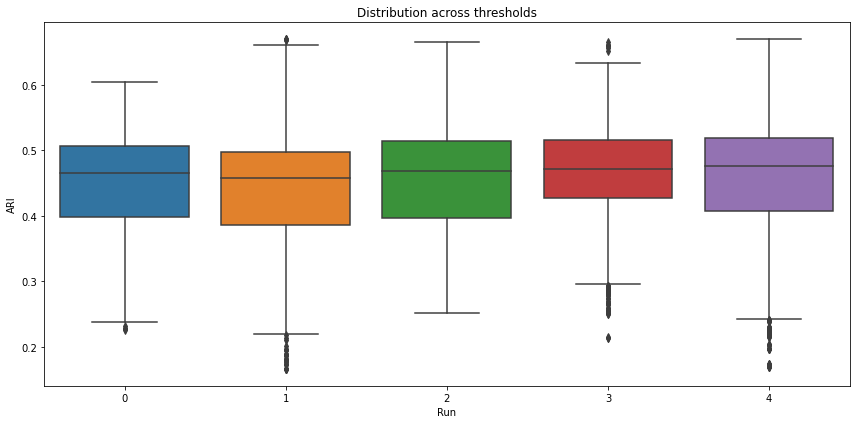

In [31]:
TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

current_results = full_result_csv 
df_long = current_results.melt(
    id_vars=["run"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('run')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="run", y="value")

plt.title(f"Distribution across thresholds")
plt.xlabel("Run")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

In [32]:
NON_TEST_SAMPLES = [sample for sample in FULL_SAMPLE_COLS if sample not in TEST_SAMPLES]

In [33]:
df_long_run_train = current_results.groupby(['run', 'threshold', 'params', 'PLDA'])[NON_TEST_SAMPLES].mean().median(axis=1).to_frame().reset_index()
df_long_run_test = current_results.groupby(['run', 'threshold', 'params', 'PLDA'])[TEST_SAMPLES].mean().median(axis=1).to_frame().reset_index()

In [34]:
df_long_run_train

,run,threshold,params,PLDA,0
0,0,5.0,"[128, 256, 128, 4]",coarse,0.464776
1,0,5.0,"[128, 256, 128, 4]",standard,0.464612
2,0,5.0,"[128, 256, 128, 8]",coarse,0.275838
3,0,5.0,"[128, 256, 128, 8]",standard,0.433771
4,0,5.0,"[128, 256, 64, 4]",coarse,0.398718
...,...,...,...,...,...
215,4,5.0,"[64, 128, 64, 8]",standard,0.389028
216,4,5.0,"[64, 256, 32, 4]",coarse,0.495520
217,4,5.0,"[64, 256, 32, 4]",standard,0.455612
218,4,5.0,"[64, 256, 32, 8]",coarse,0.286155


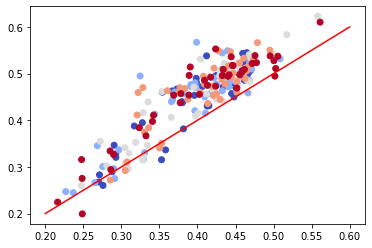

In [35]:
plt.scatter(
    df_long_run_train[0], df_long_run_test[0], c=df_long_run_train['run'], cmap='coolwarm')

plt.plot([0.2, 0.6], [0.2, 0.6], c='r')

In [265]:
model_prefix = 'DLPFC_CELLOHOOD_MODEL'


model_paths = [
    path 
    for path in os.listdir()
    if path.startswith(model_prefix) and len(path.split('_')) == 9
]

In [266]:
histories = []


for path in model_paths:
    #print(path)
    #break
    threshold = float(path.split('_')[3])
    run = int(path.split('_')[4])
    layer_size = int(path.split('_')[5])
    intermediate_layer_size = int(path.split('_')[6])
    latent_size = int(path.split('_')[7])
    num_heads = int(path.split('_')[8].split('.')[0])
    history_path = os.path.join(path, 'model_history.df')
    history = pandas.read_csv(history_path)
    history['threshold'] = threshold
    history['run'] = run
    history['layer_size'] = layer_size
    history['intermediate_layer_size'] = intermediate_layer_size
    history['latent_size'] = latent_size
    history['num_heads'] = num_heads
    histories.append(history)

In [267]:
histories_df = pandas.concat(histories, ignore_index=True)

In [268]:
histories_df

,Unnamed: 0,loss,ent,epoch_time_sec,cpu_rss_mb,gpu_process_mem_mb,threshold,run,layer_size,intermediate_layer_size,latent_size,num_heads
0,0,0.614225,2.189442,2.281831,2723.894531,9694.0,6.0,2,128,512,128,4
1,1,0.385010,2.181550,0.374381,2730.394531,9694.0,6.0,2,128,512,128,4
2,2,0.368911,2.172905,0.366957,2730.941406,9694.0,6.0,2,128,512,128,4
3,3,0.363920,2.150388,0.372274,2731.144531,9694.0,6.0,2,128,512,128,4
4,4,0.360449,2.134855,0.370215,2731.281250,9694.0,6.0,2,128,512,128,4
...,...,...,...,...,...,...,...,...,...,...,...,...
34595,95,0.163793,1.364458,0.618062,2746.859375,9694.0,5.0,0,256,1024,128,8
34596,96,0.156269,1.351750,0.615639,2746.875000,9694.0,5.0,0,256,1024,128,8
34597,97,0.149069,1.350200,0.612588,2746.882812,9694.0,5.0,0,256,1024,128,8
34598,98,0.143755,1.348245,0.615327,2746.882812,9694.0,5.0,0,256,1024,128,8


In [269]:
histories_df_last = histories_df[histories_df['Unnamed: 0'] == 99]

(array([15., 60., 92., 35., 17., 13.,  6.,  5., 32., 71.]),
 array([0.02224386, 0.04748253, 0.0727212 , 0.09795987, 0.12319855,
        0.14843722, 0.17367589, 0.19891456, 0.22415323, 0.2493919 ,
        0.27463057]),
 <BarContainer object of 10 artists>)

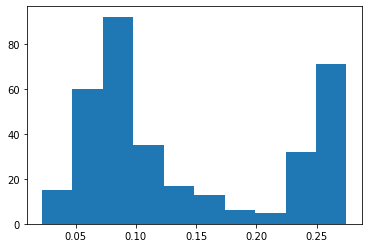

In [270]:
plt.hist(histories_df_last['loss'])

In [271]:
histories_df_last = histories_df_last.sort_values(['threshold', 'run'])

In [272]:
#df_long = df_long.sort_values(['threshold', 'run'])

In [273]:
histories_df_last

,Unnamed: 0,loss,ent,epoch_time_sec,cpu_rss_mb,gpu_process_mem_mb,threshold,run,layer_size,intermediate_layer_size,latent_size,num_heads
17999,99,0.025366,0.649542,0.676142,2713.539062,9694.0,2.0,0,128,256,64,4
5899,99,0.026003,0.705454,0.672187,2712.882812,9694.0,2.0,1,128,256,64,4
9699,99,0.022244,0.635725,0.675771,2712.167969,9694.0,2.0,2,128,256,64,4
17399,99,0.040314,0.870324,0.680027,2715.058594,9694.0,2.0,3,128,256,64,4
22099,99,0.188147,0.891555,0.683287,2712.777344,9694.0,2.0,4,128,256,64,4
...,...,...,...,...,...,...,...,...,...,...,...,...
26399,99,0.274631,1.841632,0.492153,2724.210938,9694.0,6.0,4,256,512,128,8
28399,99,0.149285,1.539808,0.381566,2751.597656,10312.0,6.0,4,64,256,32,8
31699,99,0.273632,1.845362,0.373081,2728.519531,9694.0,6.0,4,128,512,64,4
32099,99,0.087095,1.375677,0.515352,2732.312500,9694.0,6.0,4,256,1024,256,4


In [274]:
histories_df_last.shape

(346, 12)

In [275]:
grouped_results = full_result_csv.groupby(
    [
        'threshold', 
        'run', 
        'layer_size',
        'intermediate_layer_size',
        'latent_size',
        'num_heads'])[ALL_COLUMNS + ['total']].mean().reset_index()

In [276]:
total_with_loss = pandas.merge(grouped_results, histories_df_last)

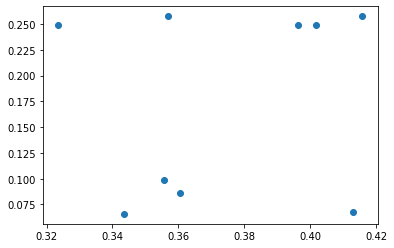

In [277]:
plt.scatter(total_with_loss['total'], total_with_loss['loss'])

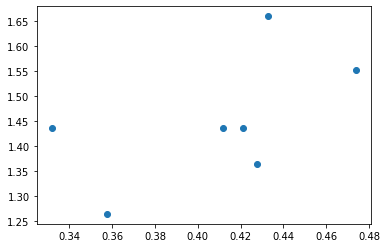

In [125]:
plt.scatter(total_with_loss['total'], total_with_loss['ent'])

In [126]:
!cat /raid/immucan/immuw/cellohood-analyses/analyses/DLPFC_ABLATION/DLPFC_CELLOHOOD_MODEL_10.0/model_class.txt

BaseWinterCellEnvironmentAEV2

In [127]:
total_with_loss

,threshold,run,layer_size,intermediate_layer_size,latent_size,num_heads,151673,151672,151507,151508,...,151674,151675,151676,total,Unnamed: 0,loss,ent,epoch_time_sec,cpu_rss_mb,gpu_process_mem_mb
0,4.0,0,128,256,64,4,0.326693,0.388412,0.354468,0.336351,...,0.341559,0.337057,0.316584,0.331752,99,0.248858,1.435852,0.476253,2714.449219,9694.0
1,4.0,1,128,256,64,4,0.452416,0.464561,0.455438,0.418402,...,0.402025,0.489382,0.430438,0.411599,99,0.248934,1.436073,0.474896,2723.273438,9694.0
2,4.0,2,128,256,64,4,0.494619,0.464345,0.480711,0.457767,...,0.364066,0.476608,0.451852,0.421255,99,0.249168,1.436158,0.482845,2713.324219,9694.0
3,4.0,3,128,256,64,4,0.429771,0.378806,0.389835,0.340126,...,0.373530,0.415687,0.401576,0.357387,99,0.065835,1.264581,0.469466,2721.000000,9694.0
4,4.0,4,128,256,64,4,0.463141,0.480592,0.472095,0.467077,...,0.457109,0.460877,0.452891,0.427622,99,0.068132,1.363497,0.465932,2717.515625,9694.0
5,5.0,0,128,256,64,4,0.474599,0.458339,0.518301,0.482870,...,0.389625,0.467372,0.466865,0.432746,99,0.257347,1.660125,0.406852,2722.472656,9694.0
6,5.0,1,128,256,64,4,0.521566,0.535584,0.551910,0.494224,...,0.449154,0.508783,0.508309,0.473973,99,0.086430,1.552934,0.417232,2722.406250,9694.0


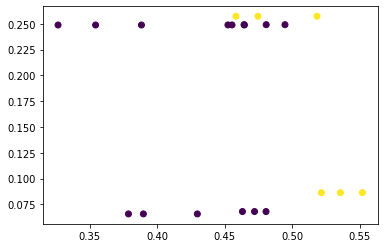

In [128]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['loss'], c=total_with_loss['threshold'])

In [129]:
full_result_csv.groupby(['params', 'run'])['total'].max().max()

0.488508815861165

In [130]:
uniques = full_result_csv.groupby(['threshold', 'run', 'layer_size', 'intermediate_layer_size', 'latent_size', 'num_heads']).size().reset_index()

In [131]:
from sklearn.decomposition import PCA
import tqdm

results = {}

for _, row in tqdm.tqdm(uniques.iterrows()):
    distance_threshold = row['threshold']
    run_nb = int(row['run'])
    layer_size = int(row['layer_size'])
    intermediate_layer_size = int(row['intermediate_layer_size'])
    latent_size = int(row['latent_size'])
    num_heads = int(row['num_heads'])
    #try:
    cello_prediction_path = f"DLPFC_CP_{distance_threshold}_{run_nb}_{layer_size}_{intermediate_layer_size}_{latent_size}_{num_heads}"
    smoothed_df_result = cellohood.load_cello_prediction(
        path=cello_prediction_path
    )
    pca = PCA()
    transformed = pca.fit_transform(smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values)
    results[(distance_threshold, run_nb, layer_size, intermediate_layer_size, num_heads)] = pca.explained_variance_
#     except:
#         print(row)
#         continue
                                                                                                 

6it [00:09,  1.59s/it]


KeyboardInterrupt: 

In [68]:
from collections import defaultdict

results_losses = defaultdict(list)

for _, row in full_result_csv.iterrows():
    distance_threshold = row['threshold']
    run_nb = int(row['run'])
    layer_size = int(row['layer_size'])
    intermediate_layer_size = int(row['intermediate_layer_size'])
    latent_size = int(row['latent_size'])
    num_heads = int(row['num_heads'])
    results_losses[(distance_threshold, run_nb, layer_size, intermediate_layer_size, num_heads)].append(row['total'])

In [119]:
import numpy


first_rate = [val_[0] for val_ in results.values()]
second_rate = [val_[1] for val_ in results.values()]
first_ratio = [val_[0] / numpy.sum(val_) for val_ in results.values()]
second_ratio = [val_[1] / numpy.sum(val_) for val_ in results.values()]
first_two_ratio = [(val_[0] + val_[1]) / numpy.sum(val_) for val_ in results.values()]
losses = [numpy.max(results_losses[key]) for key in results.keys()]

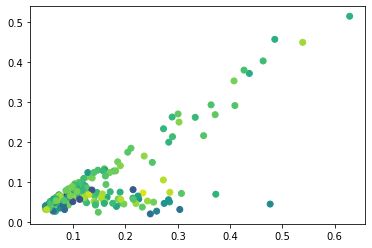

In [120]:
plt.scatter(first_rate, second_rate, c=losses)

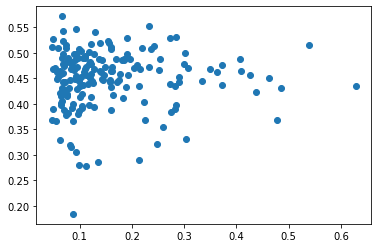

In [121]:
plt.scatter(first_rate, losses)

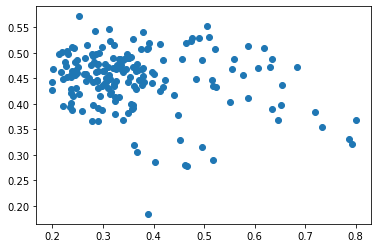

In [122]:
plt.scatter(first_ratio, losses)

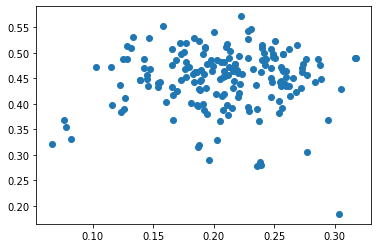

In [123]:
plt.scatter(second_ratio, losses)

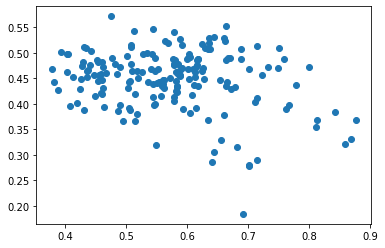

In [124]:
plt.scatter(first_two_ratio, losses)

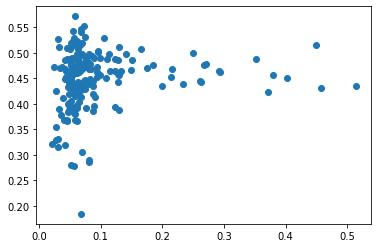

In [125]:
plt.scatter(second_rate, losses)

In [24]:
import numpy


full_result_csv_rg[full_result_csv_rg['total'].apply(lambda x: numpy.isclose(x,  0.45983510031551394))]

,run,params,threshold,151673,151672,151507,151508,151669,151509,151671,151510,151670,151674,151675,151676,total
3,1,"[128, 256, 64, 4]",5.0,0.521566,0.535584,0.55191,0.494224,0.391624,0.465697,0.440678,0.459835,0.360306,0.449154,0.508783,0.508309,0.459835


In [160]:
import cellohood

distance_threshold = 4.0
run_nb = 0
layer_size = 128
intermediate_layer_size = 256
latent_size = 64
num_heads = 4

In [161]:
FULL_CELLO_BAG_DF_PATH = f"DLPFC_CB_{distance_threshold}"

CELLO_PREDICTION_PATH = f"DLPFC_CP_SPLIT_{distance_threshold}_{run_nb}_{layer_size}_{intermediate_layer_size}_{latent_size}_{num_heads}"

In [162]:
CELLO_PREDICTION_PATH

'DLPFC_CP_SPLIT_4.0_0_128_256_64_4'

In [163]:
bag_cello_df = cellohood.load_bag_cello_df(
    path=FULL_CELLO_BAG_DF_PATH
)

In [164]:
smoothed_df_result = cellohood.load_cello_prediction(
    path=CELLO_PREDICTION_PATH
)

In [165]:
from sklearn.decomposition import PCA

smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns]

,0cs,1cs,2cs,3cs,4cs,5cs,6cs,7cs,8cs,9cs,...,54cs,55cs,56cs,57cs,58cs,59cs,60cs,61cs,62cs,63cs
0,0.119622,0.046891,-0.316969,0.215509,-0.010908,-0.130995,0.074678,0.168841,0.253070,-0.286256,...,-0.066990,-0.189064,0.169614,0.131575,-0.091061,-0.067343,0.022319,-0.197916,-0.013756,0.158130
1,0.126073,0.059976,-0.312230,0.202871,-0.016954,-0.141460,0.068148,0.178205,0.264810,-0.295879,...,-0.066726,-0.189152,0.185499,0.143064,-0.097491,-0.075950,0.022337,-0.206546,-0.024936,0.183891
2,0.094052,0.003948,-0.316167,0.217522,0.006608,-0.114917,0.045101,0.155380,0.221703,-0.256229,...,-0.062103,-0.186007,0.159493,0.092128,-0.100512,-0.065432,0.043192,-0.174686,0.031510,0.089408
3,0.107605,0.030609,-0.317351,0.208790,-0.006732,-0.127843,0.058455,0.167146,0.248114,-0.277312,...,-0.063355,-0.189581,0.166415,0.121459,-0.096720,-0.072326,0.033764,-0.193458,0.005368,0.139467
4,0.118594,0.102700,-0.130169,0.069256,-0.015948,-0.140433,-0.007702,0.167400,0.184406,-0.210329,...,-0.025162,-0.108239,0.285063,0.085471,-0.123601,-0.048813,0.030757,-0.166344,-0.051699,0.197312
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47676,-0.050896,-0.031219,-0.321882,0.100537,0.035932,-0.096699,-0.136682,0.031355,0.176244,-0.103780,...,-0.127960,-0.148011,0.036735,-0.007056,-0.160807,-0.172303,0.083928,-0.094506,0.095797,-0.081528
47677,-0.049677,-0.014551,-0.311830,0.097681,0.027909,-0.101104,-0.116515,0.036389,0.162028,-0.102263,...,-0.122890,-0.140734,0.051772,-0.021485,-0.165835,-0.163990,0.079293,-0.101573,0.076734,-0.075324
47678,0.146485,-0.080854,-0.174287,0.150789,0.034064,-0.044131,-0.029558,0.098276,0.187589,-0.207542,...,-0.034559,-0.133956,0.058320,0.207926,-0.000667,-0.067971,0.048791,-0.123466,0.087786,0.112919
47679,0.127412,-0.112232,-0.160360,0.136769,0.045960,-0.037974,-0.069692,0.083422,0.174823,-0.182253,...,-0.035008,-0.128892,0.053888,0.191034,-0.004937,-0.076494,0.066218,-0.104256,0.122379,0.084645


In [166]:
pca = PCA()

In [167]:
transformed = pca.fit_transform(smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values)
decomposed = transformed

(array([[0.000e+00, 1.000e+00, 5.400e+01, 3.120e+02, 9.070e+02, 7.420e+02,
         1.000e+01, 0.000e+00, 0.000e+00, 0.000e+00],
        [0.000e+00, 1.320e+02, 6.370e+02, 1.206e+03, 1.480e+03, 1.837e+03,
         7.070e+02, 8.000e+00, 0.000e+00, 0.000e+00],
        [7.300e+01, 5.240e+02, 1.050e+03, 9.690e+02, 9.770e+02, 1.431e+03,
         1.864e+03, 3.660e+02, 1.000e+00, 0.000e+00],
        [1.750e+02, 7.180e+02, 6.980e+02, 7.670e+02, 6.730e+02, 1.051e+03,
         1.563e+03, 6.520e+02, 9.000e+00, 0.000e+00],
        [5.400e+01, 2.380e+02, 8.700e+01, 2.510e+02, 4.370e+02, 8.460e+02,
         1.247e+03, 7.560e+02, 3.900e+01, 0.000e+00],
        [0.000e+00, 1.380e+02, 2.520e+02, 2.110e+02, 4.650e+02, 9.130e+02,
         1.202e+03, 6.990e+02, 5.000e+01, 2.000e+00],
        [1.920e+02, 5.280e+02, 4.690e+02, 4.620e+02, 6.250e+02, 1.423e+03,
         1.311e+03, 5.690e+02, 2.700e+01, 0.000e+00],
        [2.140e+02, 1.059e+03, 3.790e+02, 5.580e+02, 1.111e+03, 1.857e+03,
         1.760e+03, 3.

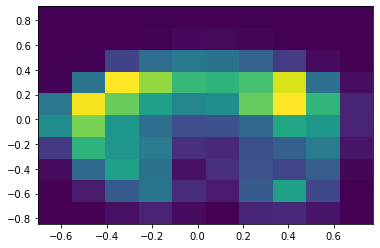

In [168]:
plt.hist2d(
    transformed[:, 0],
    transformed[:, 1],
)

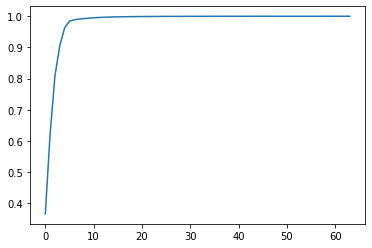

In [169]:
plt.plot(pca.explained_variance_ratio_.cumsum())

In [170]:
import numpy

variance_ratios = pca.explained_variance_ratio_.cumsum()
nb_of_standard_components = max(numpy.abs(variance_ratios - 0.75).argmin(), 2)

In [171]:
nb_of_standard_components

2

In [172]:
variance_ratios

array([0.36541104, 0.62293315, 0.80879639, 0.90547824, 0.96240667,
       0.98431925, 0.98860327, 0.99099291, 0.99240915, 0.99377827,
       0.99497908, 0.99601589, 0.99664445, 0.9971851 , 0.99768972,
       0.99804352, 0.99834651, 0.99856823, 0.99874978, 0.99890892,
       0.99903872, 0.99916286, 0.9992782 , 0.99936677, 0.99943759,
       0.99949242, 0.99954575, 0.99959431, 0.99963727, 0.99967551,
       0.99971299, 0.99974637, 0.99977566, 0.99980105, 0.99982566,
       0.999846  , 0.99986444, 0.99988037, 0.99989573, 0.99990995,
       0.99992135, 0.9999322 , 0.9999415 , 0.99995001, 0.99995789,
       0.9999643 , 0.99997026, 0.99997604, 0.99997957, 0.99998256,
       0.9999853 , 0.99998789, 0.99999042, 0.99999241, 0.99999393,
       0.99999511, 0.99999619, 0.99999711, 0.99999792, 0.9999986 ,
       0.99999912, 0.9999995 , 0.99999978, 1.        ])

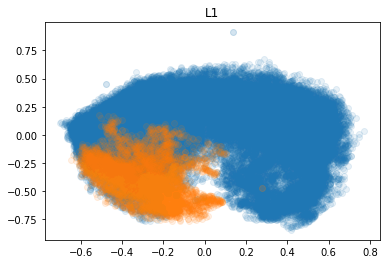

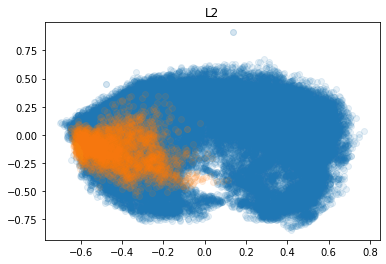

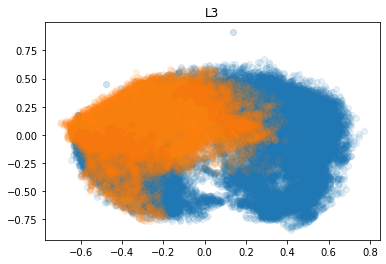

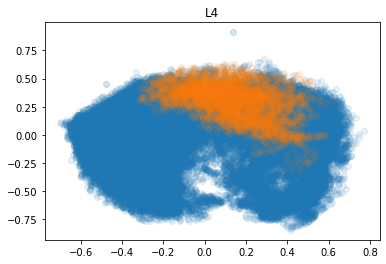

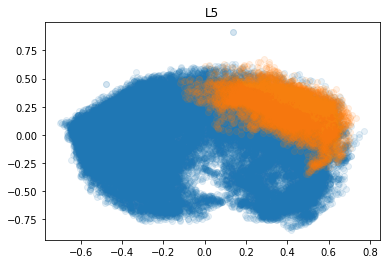

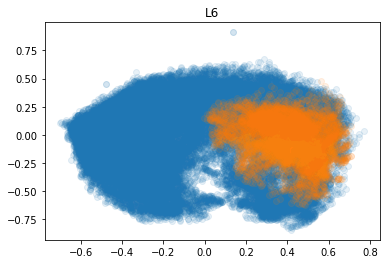

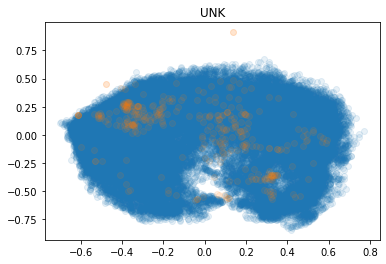

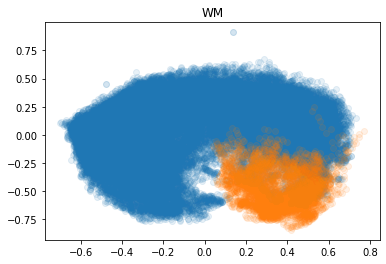

In [173]:
layers_ = sorted(list(set(bag_cello_df.cell_df['layer'])))


for layer in layers_:
    plt.title(layer)
    plt.scatter(
        transformed[bag_cello_df.cell_df['layer'] != layer, 0],
        transformed[bag_cello_df.cell_df['layer'] != layer, 1],
        alpha=0.1,
    )
    plt.scatter(
        transformed[bag_cello_df.cell_df['layer'] == layer, 0],
        transformed[bag_cello_df.cell_df['layer'] == layer, 1],
        alpha=0.1,
    )
    plt.show()


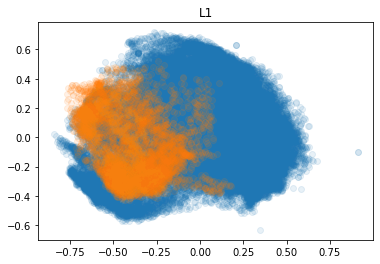

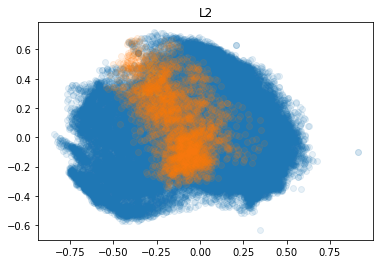

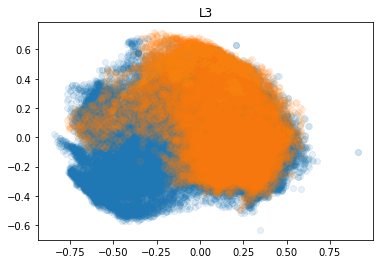

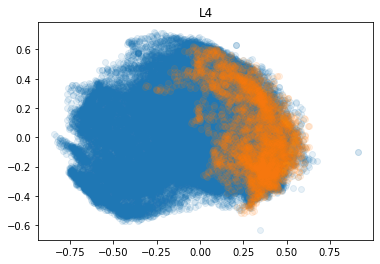

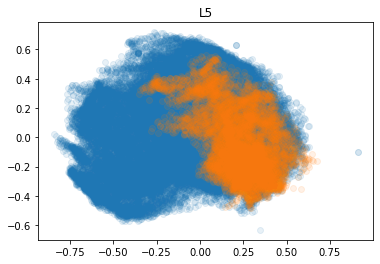

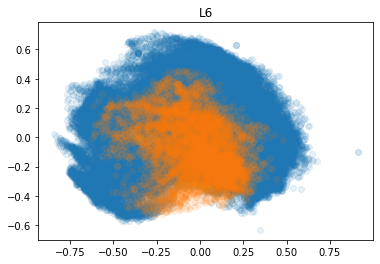

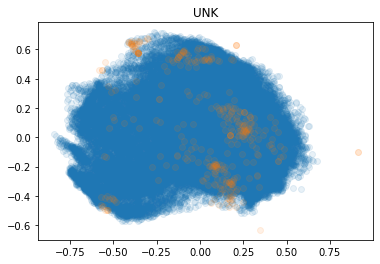

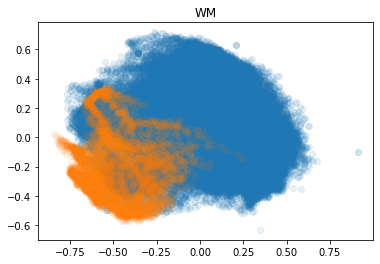

In [181]:
layers_ = sorted(list(set(bag_cello_df.cell_df['layer'])))


for layer in layers_:
    plt.title(layer)
    plt.scatter(
        transformed[bag_cello_df.cell_df['layer'] != layer, 1],
        transformed[bag_cello_df.cell_df['layer'] != layer, 2],
        alpha=0.1,
    )
    plt.scatter(
        transformed[bag_cello_df.cell_df['layer'] == layer, 1],
        transformed[bag_cello_df.cell_df['layer'] == layer, 2],
        alpha=0.1,
    )
    plt.show()


  0%|                                                                                                                                                                                          | 0/10 [00:00<?, ?it/s]

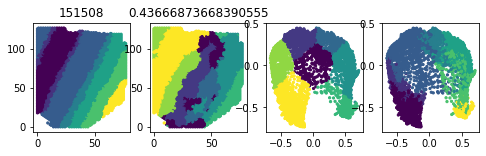

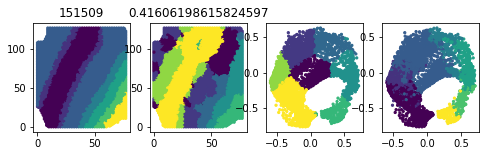

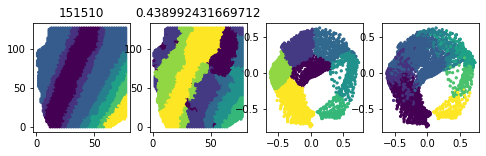

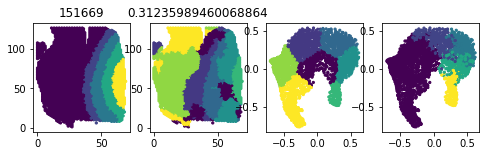

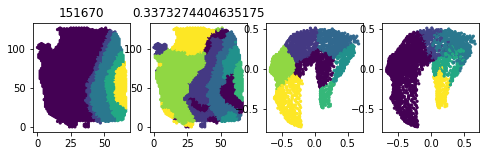

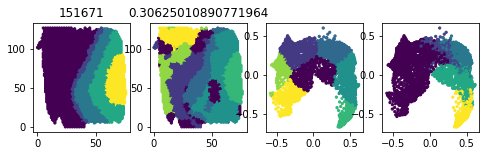

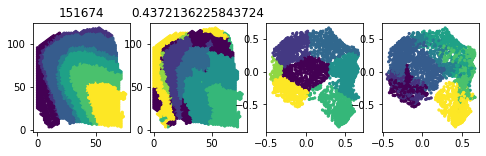

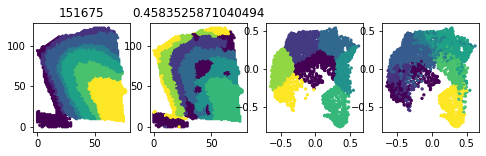

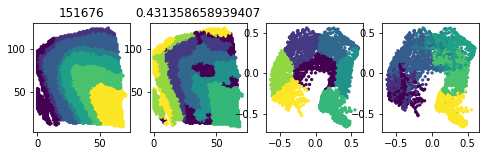

 10%|█████████████████▊                                                                                                                                                                | 1/10 [00:05<00:51,  5.70s/it]

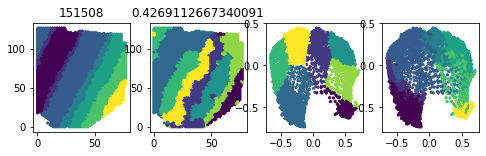

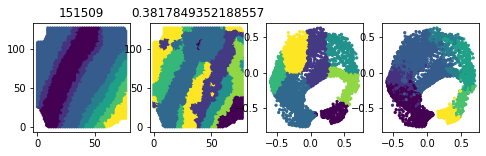

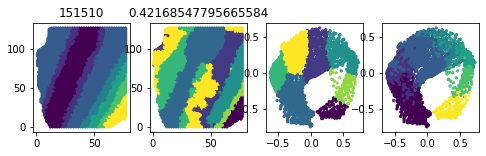

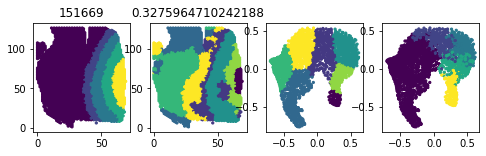

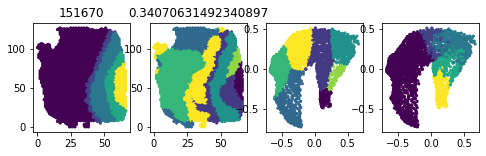

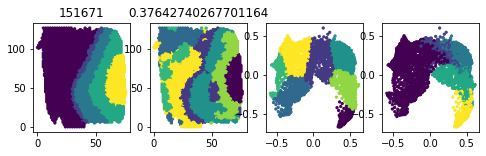

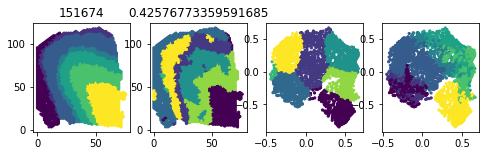

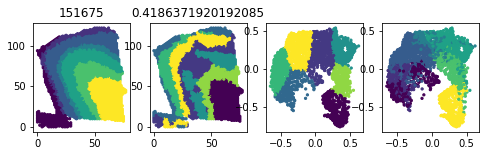

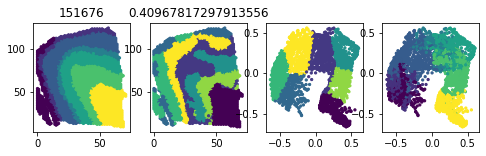

 20%|███████████████████████████████████▌                                                                                                                                              | 2/10 [00:09<00:38,  4.81s/it]

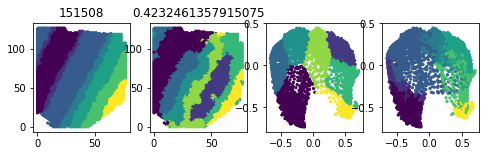

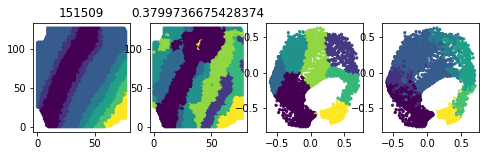

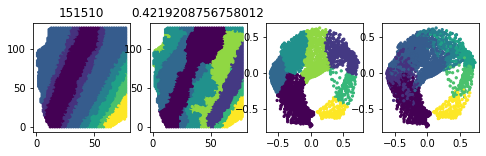

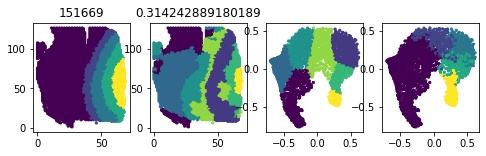

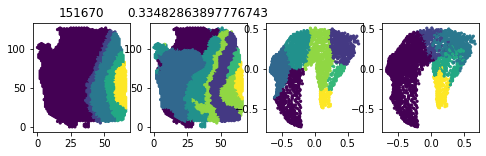

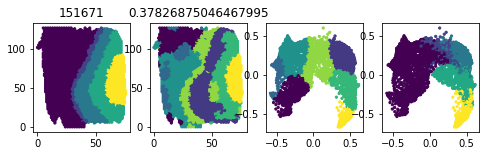

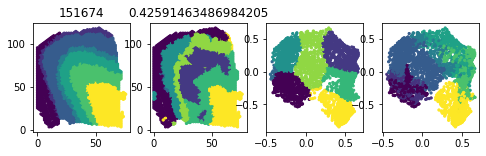

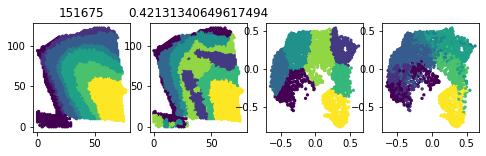

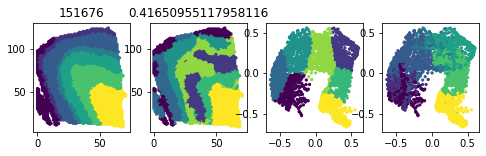

 30%|█████████████████████████████████████████████████████▍                                                                                                                            | 3/10 [00:14<00:32,  4.62s/it]

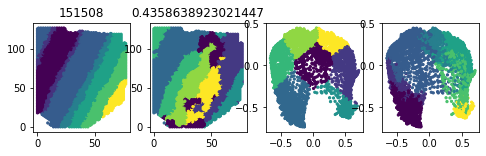

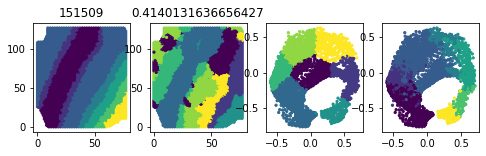

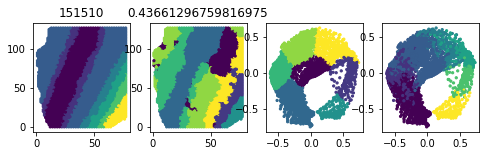

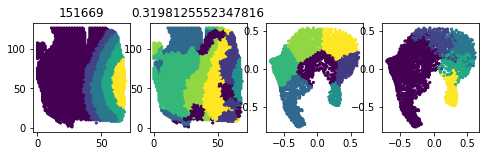

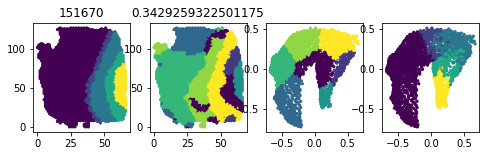

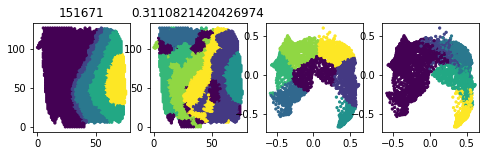

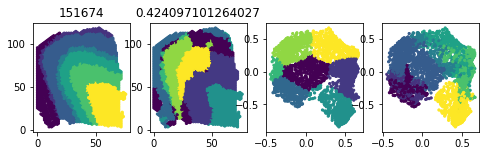

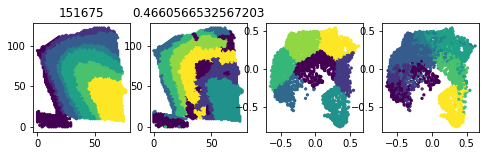

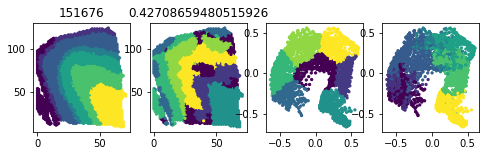

 40%|███████████████████████████████████████████████████████████████████████▏                                                                                                          | 4/10 [00:19<00:28,  4.78s/it]

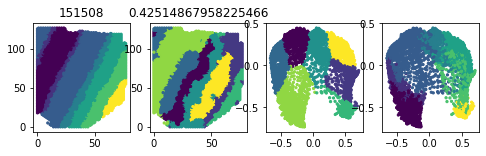

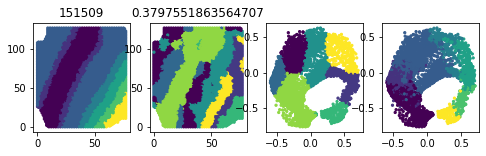

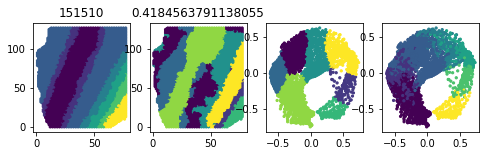

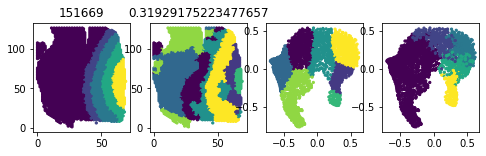

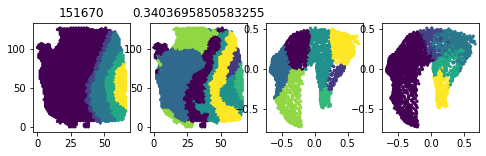

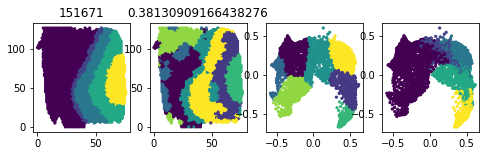

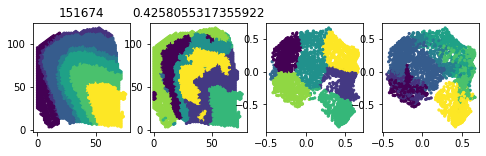

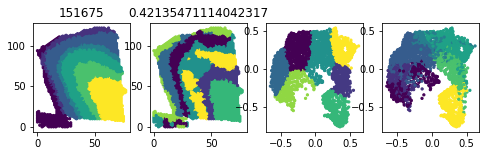

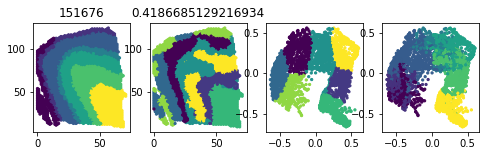

 50%|█████████████████████████████████████████████████████████████████████████████████████████                                                                                         | 5/10 [00:23<00:23,  4.70s/it]

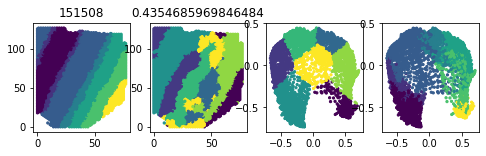

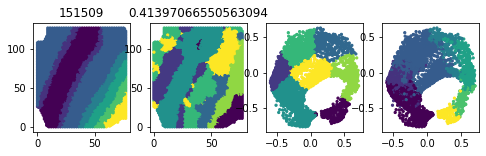

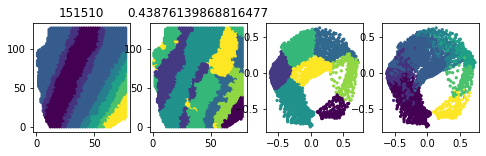

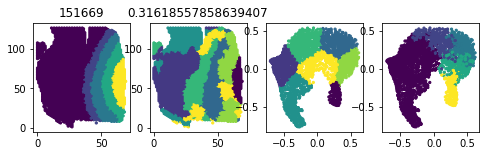

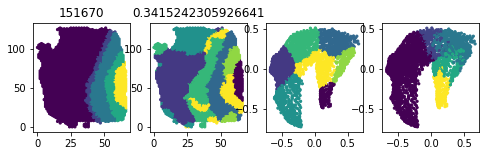

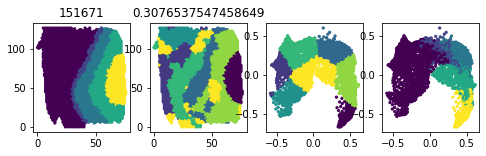

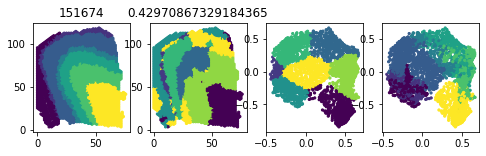

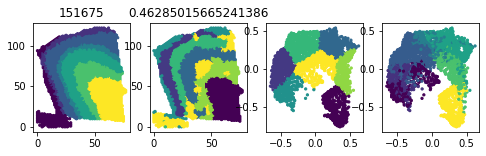

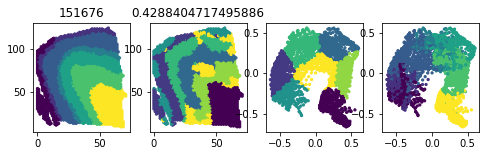

 60%|██████████████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                       | 6/10 [00:28<00:18,  4.71s/it]

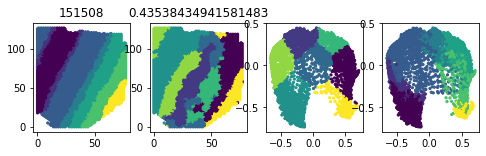

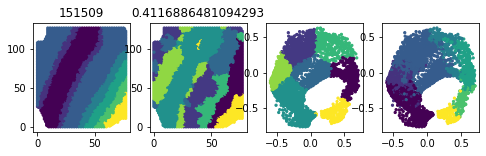

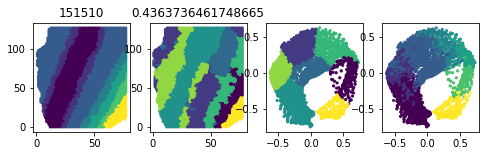

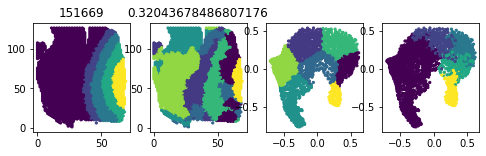

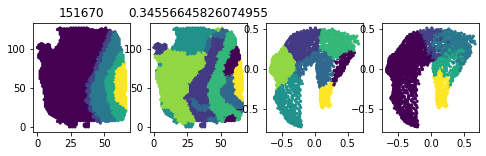

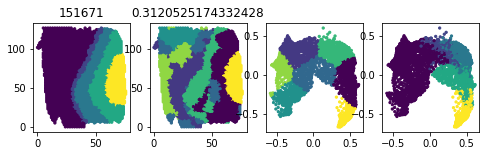

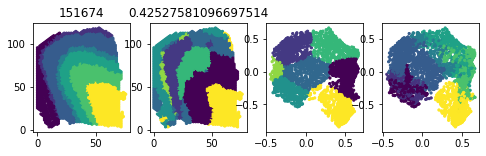

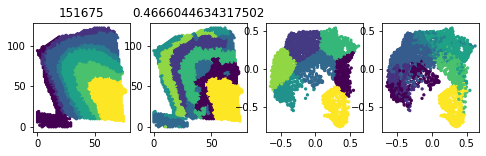

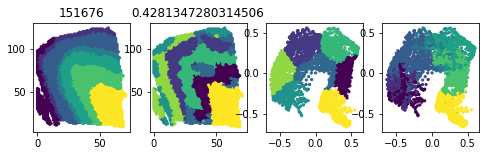

 70%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                                     | 7/10 [00:34<00:15,  5.20s/it]

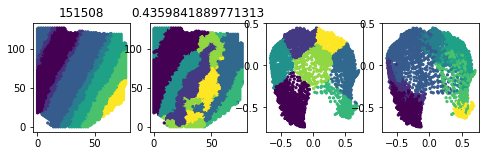

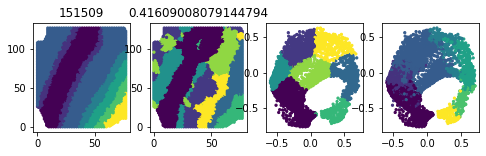

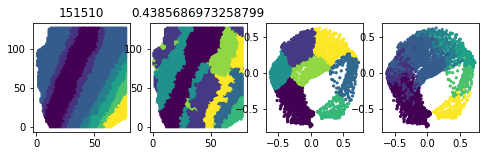

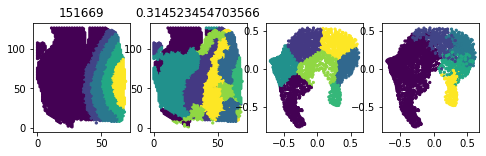

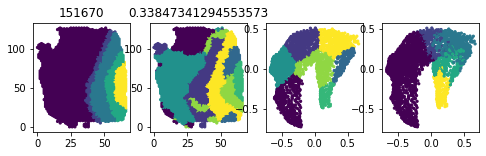

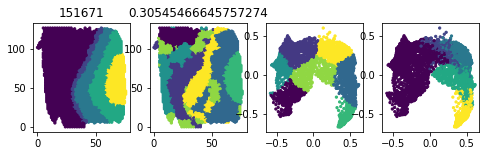

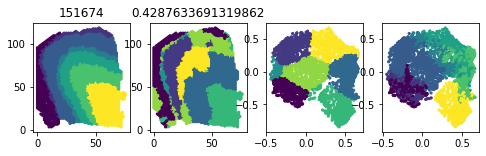

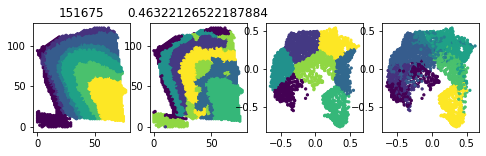

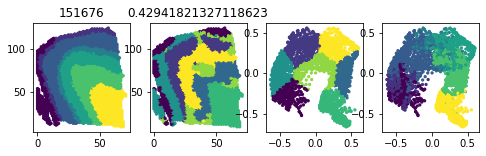

 80%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                   | 8/10 [00:39<00:09,  4.97s/it]

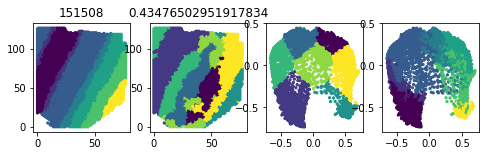

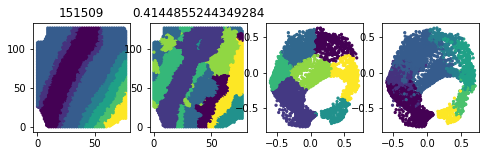

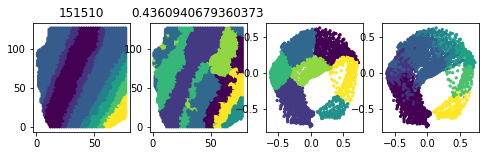

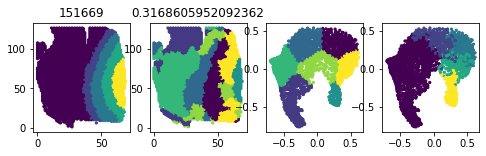

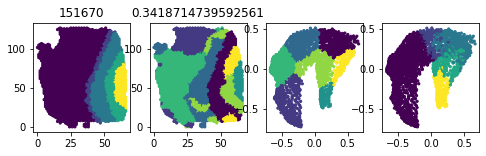

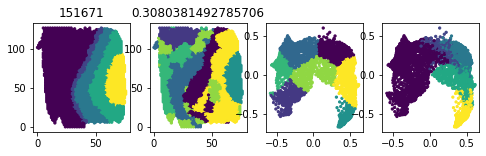

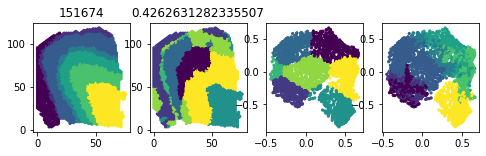

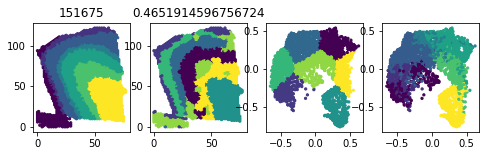

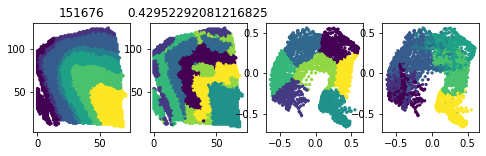

 90%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                 | 9/10 [00:44<00:04,  4.89s/it]

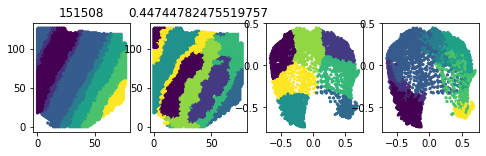

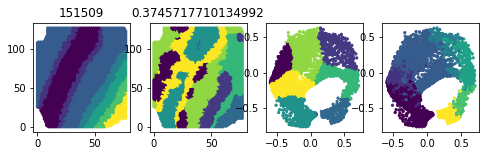

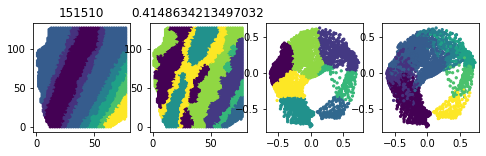

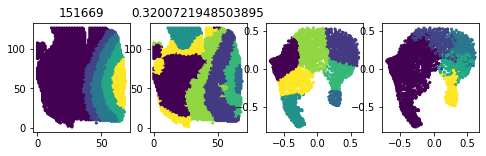

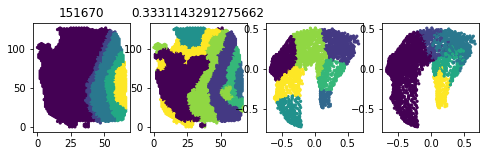

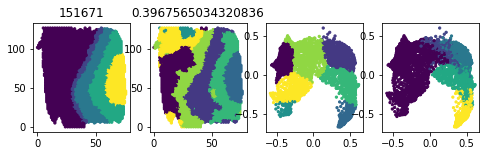

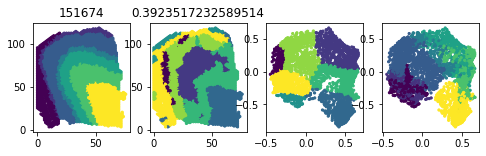

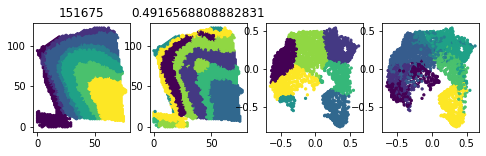

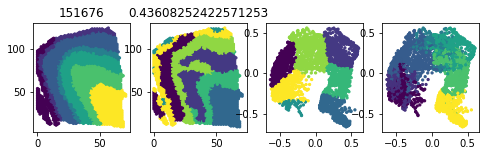

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:49<00:00,  4.91s/it]


In [175]:
from collections import defaultdict
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score


from scipy.stats import ttest_rel
import numpy
import tqdm



NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_aris = defaultdict(list)
clusterers = []
variables = [0, 1]

train_cello_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = decomposed[
        bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES),
    ][:, variables]# / decomposer.explained_variance_ratio_[:2]
    current_clusterer.fit(training_ld)
    clusterers.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld[train_cello_df['sample'] == sample]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris[sample].append(current_ari)
        
        plt.figure(figsize=(8, 2))
        plt.subplot(1, 4, 1)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_non_unk_df['layer'].apply(lambda x: layers_.index(x)),
            s=5,
        )
        plt.title(sample)
        plt.subplot(1, 4, 2)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_preds,
            s=5,
        )
        plt.title(current_ari)
        plt.subplot(1, 4, 3)
        plt.scatter(
            sample_ld[:, 0],
            sample_ld[:, 1],
            c=sample_preds,
            s=5,
        )
        plt.subplot(1, 4, 4)
        plt.scatter(
            sample_ld[:, 0],
            sample_ld[:, 1],
            c=sample_gt,
            s=5,
        )
        plt.show()

In [176]:
numpy.median([numpy.mean(val_) for val_ in sample_to_aris.values()])

0.4241161328933057

In [177]:
training_ld = decomposed[
        bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES),
    ][:, variables]

In [178]:
cellcharter = pandas.read_csv('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/ARI_CellCharter_hvgs5000_nlatent5_nhoodlayers4_gpu_joint.csv')
cellcharter_means = cellcharter.values[:, 1:].mean(axis=1)

In [179]:
cellcharter

,Unnamed: 0,0,1,2,3,4,5,6,7,8,9
0,151508,0.551989,0.531160,0.565399,0.495963,0.539644,0.513442,0.488242,0.433863,0.529117,0.486767
1,151509,0.562837,0.503530,0.503492,0.514707,0.508050,0.545168,0.522232,0.588150,0.482966,0.507954
2,151510,0.546166,0.500341,0.489382,0.516366,0.522936,0.522327,0.502971,0.514983,0.493624,0.480401
3,151669,0.377316,0.392555,0.362002,0.393196,0.380377,0.316954,0.374402,0.314425,0.392068,0.398517
4,151670,0.354959,0.386236,0.355353,0.426403,0.354900,0.337693,0.376711,0.302594,0.369035,0.401723
5,151671,0.442209,0.447159,0.417787,0.416442,0.422872,0.389442,0.379203,0.320688,0.461197,0.338430
6,151674,0.621694,0.601581,0.553034,0.574313,0.514512,0.583810,0.563349,0.480494,0.595100,0.503460
7,151675,0.590321,0.602804,0.588385,0.579080,0.558047,0.622954,0.552946,0.502845,0.593562,0.508803
8,151676,0.572769,0.567461,0.525519,0.536116,0.552884,0.571575,0.523123,0.436720,0.568823,0.461978


In [180]:
!ls /raid/immucan/immuw/cellohood_artifacts/DLPFC/DLPFC_CELLOHOOD_MODEL/

ctr.json    model_class.txt   model_weights.h5	training_params.json
model.json  model_history.df  scaler.joblib


In [296]:
!cat /raid/immucan/immuw/cellohood_artifacts/DLPFC/DLPFC_CELLOHOOD_MODEL/model.json

{
    "output_size": 5,
    "max_neighborhood_size": 10,
    "latent_size": 64,
    "layer_size": 128,
    "intermediate_layer_size": 256
}

In [91]:
import cellohood


old_one = cellohood.load_bag_cello_df(
    '/raid/immucan/immuw/cellohood_artifacts/DLPFC/DLPFC_CB/'
)

(array([3.1500e+02, 8.2180e+03, 1.7364e+04, 1.1923e+04, 6.1790e+03,
        2.5850e+03, 8.5600e+02, 2.1300e+02, 2.7000e+01, 1.0000e+00]),
 array([-2.514193  , -1.70663795, -0.8990829 , -0.09152785,  0.7160272 ,
         1.52358225,  2.3311373 ,  3.13869235,  3.9462474 ,  4.75380245,
         5.5613575 ]),
 <BarContainer object of 10 artists>)

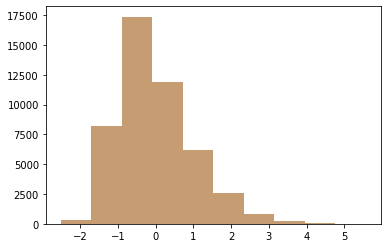

In [101]:
plt.hist(bag_cello_df.cell_df['SCVI5:1'], alpha=0.5)
plt.hist(old_one.cell_df['SCVI5:1'], alpha=0.5)

In [374]:
dir(cellohood)

['BagCelloDf',
 'CelloPrediction',
 '__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 'apply_arcsinh_to_bag_cello_df',
 'data_processing',
 'get_latent_directions',
 'get_latent_directions_predictions',
 'get_loss_on_cello_df',
 'load_bag_cello_df',
 'load_cello_prediction',
 'load_cello_train_result',
 'models',
 'run_prediction_on_cello_df',
 'save_bag_cello_df',
 'save_cello_prediction',
 'save_cello_train_result',
 'smooth_cellohood_prediction',
 'split_bag_cello_df_by',
 'standardize_bag_cello_df',
 'summarize_latent_direction_result',
 'train',
 'training',
 'transform_df_to_bag_cello_df']